# Case Study 4: Healthcare Electrification in Uganda

**Question.** The Ministry of Health has **USD 1,000,000** for health-facility electrification. Which facilities should be funded first?

**Approach.**
1. **Rank facilities** (Part 1). Candidates are facilities with no power or off-grid power. Each is scored under three lenses, then merged:
   - **P: poorest patients** (population served x poverty of the area, from the Relative Wealth Index)
   - **B: most births** (population served x maternity-capacity weight by facility level, a proxy because no births data exist)
   - **R: regional balance** (budget quotas by region, proportional to population)
   - **Final = (2P + 3B + 1R) / 6**, using the weights set for this study.
2. **Select the budget** (Part 2). Fund facilities down the final ranking within the budget, compare to the single-lens plans and to a pure value-for-money plan, and test cost sensitivity.

**Supply side.** Distance to the grid (distribution lines, transformers), planned lines and minigrids decide the electrification route and are reported for every facility. They do not change the rank (agreed design).

**Data (all in `data/`, from Energy Access Explorer, Uganda):** health facilities (WRI / Ministry of Health, 2023), Relative Wealth Index raster, distribution lines (existing and planned), minigrids, transformers.

**Run:** open this notebook with its working directory set to the `submission` folder and run all cells. Results are written to `data/results/`.

> **Every assumption is a named parameter in the cells below.** The most important ones: ERT facilities excluded, level weights for births, the 5 km grid-route cutoff, USD 17,700 base cost per facility (derived from a UNDP Zimbabwe figure, **not verified**), 10% maintenance reserve.

In [1]:
# Setup: install any package that is missing, then the next cell imports them.
import importlib.util, subprocess, sys
REQUIRED = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "matplotlib": "matplotlib",
            "tifffile": "tifffile", "shapely": "shapely", "pyproj": "pyproj"}      # import name -> pip name
missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already installed:", ", ".join(REQUIRED.values()))

All required packages are already installed: numpy, pandas, scipy, matplotlib, tifffile, shapely, pyproj


In [2]:
import json, os
import numpy as np, pandas as pd, tifffile, shapely
import matplotlib.pyplot as plt
from shapely.geometry import shape
from pyproj import Transformer
from scipy.spatial import cKDTree

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
DATA = "data"
OUT = os.path.join(DATA, "results"); os.makedirs(OUT, exist_ok=True)

# ---- Part 1 parameters ----
WEIGHTS = {"P": 2, "B": 3, "R": 1}             # poorest, births, regional balance
CANDIDATE_STATUS = ["No", "Off-grid"]          # "Data unavailable" is excluded
EXCLUDE_ERT = True                             # ERT1/2/3 = already in the Energy for Rural Transformation programme (assumption)
REGION_COL = "REGION"                          # try "SUB_REGION" for finer balance
LEVEL_BIRTH_W = {"HC II": 0.25, "Clinic": 0.5, "HC III": 1.0, "HC IV": 2.0,
                 "Hospital": 3.0, "RRH": 4.0, "NRH": 4.0, "SC": 0.25}   # maternity capacity by level (assumption)
GRID_ROUTE_KM = 5.0                            # within this distance of a line/transformer -> grid extension (assumption)

# ---- Part 2 parameters ----
BUDGET = 1_000_000
BASE_COST = 17_700        # USD per facility. Derived: UNDP Zimbabwe Solar for Health, USD 18.5M / 1,044 systems. NOT verified.
MAINT_RESERVE = 0.10      # share of the budget held back for maintenance (assumption)
GRID_DISCOUNT = 1.0       # base case: grid-route facilities cost the same (no sourced grid cost); tested in sensitivity
SCALE_EXP = 0.6           # cost ~ energy need^0.6, economies of scale (assumption)
SCALE_CLIP = (0.4, 3.0)

## Part 1. Rank facilities

### 1.1 Load facilities and define the candidate pool

In [3]:
g = json.load(open(os.path.join(DATA, "uganda_health_facilities_eae.geojson"), encoding="utf-8"))
fac = pd.DataFrame([f["properties"] for f in g["features"]])
for c in ["LAT", "LONG", "pop", "Catch_pop", "Avg_kWh_d", "Peak_pw_kW", "Beds"]:
    fac[c] = pd.to_numeric(fac[c], errors="coerce")

fac["in_pool"] = fac.ELECTRIFIC.isin(CANDIDATE_STATUS)
if EXCLUDE_ERT:
    fac["in_pool"] &= fac.ERT_status.eq("No")
pool_n = int(fac.in_pool.sum())

print(f"All facilities: {len(fac):,}")
print(fac.ELECTRIFIC.value_counts().to_string())
print(f"\nCandidate pool (status {CANDIDATE_STATUS}{', ERT_status = No' if EXCLUDE_ERT else ''}): {pool_n:,}")
display(fac[fac.in_pool].groupby(["ELECTRIFIC", "LEVEL"]).size().unstack(fill_value=0))

All facilities: 4,938
ELECTRIFIC
On-grid             2673
Off-grid            1553
No                   582
Data unavailable     130

Candidate pool (status ['No', 'Off-grid'], ERT_status = No): 1,559


LEVEL,Clinic,HC II,HC III,HC IV,Hospital
ELECTRIFIC,,,,,
No,2,547,31,0,0
Off-grid,29,705,234,6,5


### 1.2 Poverty: sample the Relative Wealth Index at each facility

In [4]:
to_utm = Transformer.from_crs(4326, 32636, always_xy=True)   # metres, for distances
to_merc = Transformer.from_crs(4326, 3857, always_xy=True)   # the RWI raster is in Web Mercator
fac["x"], fac["y"] = to_utm.transform(fac.LONG.values, fac.LAT.values)
fac["mx"], fac["my"] = to_merc.transform(fac.LONG.values, fac.LAT.values)

pg = tifffile.TiffFile(os.path.join(DATA, "relative_wealth_index.tif")).pages[0]
arr = pg.asarray().astype(float)[..., 0]
sx, sy, _ = pg.tags[33550].value; _, _, _, ox, oy, _ = pg.tags[33922].value      # pixel size, top-left origin
col = np.floor((fac.mx - ox) / sx).astype(int); row = np.floor((oy - fac.my) / sy).astype(int)
ok = (row >= 0) & (row < arr.shape[0]) & (col >= 0) & (col < arr.shape[1])
rwi = np.full(len(fac), np.nan); rwi[ok] = arr[row[ok], col[ok]]
rwi[rwi <= -2.0] = np.nan                                  # -2 is the raster's no-data value
fac["rwi_raw"] = rwi

# fallback for facilities outside the raster: district median, then region, then national
fac["rwi"] = fac.rwi_raw
fac["rwi_src"] = np.where(fac.rwi_raw.notna(), "pixel", "")
for lvl in ["DISTRICT", REGION_COL]:
    med = fac.groupby(lvl).rwi_raw.transform("median"); m = fac.rwi.isna() & med.notna()
    fac.loc[m, "rwi"] = med[m]; fac.loc[m, "rwi_src"] = lvl.lower() + "_median"
m = fac.rwi.isna(); fac.loc[m, "rwi"] = fac.rwi_raw.median(); fac.loc[m, "rwi_src"] = "national_median"
print("RWI source for candidates:", fac[fac.in_pool].rwi_src.value_counts().to_dict())

RWI source for candidates: {'pixel': 1524, 'district_median': 35}


### 1.3 Supply side: distance to the grid
Exact distances (km) from each facility to the nearest distribution line, planned line, minigrid and transformer.

In [5]:
def read_geoms(name):
    gg = json.load(open(os.path.join(DATA, name), encoding="utf-8"))
    return [shape(f["geometry"]) for f in gg["features"]]

def to_utm_geom(geoms):
    return [shapely.transform(gm, lambda c: np.column_stack(to_utm.transform(c[:, 0], c[:, 1]))) for gm in geoms]

pts = shapely.points(fac.x.values, fac.y.values)
def min_dist_km(geoms):
    d = np.full(len(fac), np.inf)
    for gm in to_utm_geom(geoms):
        d = np.minimum(d, shapely.distance(pts, gm))
    return d / 1000.0

fac["km_dist_line"] = min_dist_km(read_geoms("distribution_lines.geojson"))
fac["km_planned_line"] = min_dist_km(read_geoms("distribution_lines_planned.geojson"))
fac["km_minigrid"] = min_dist_km(read_geoms("minigrids.geojson"))

txp = []
for gm in read_geoms("transformers.geojson"):
    for p in (gm.geoms if hasattr(gm, "geoms") else [gm]): txp.append((p.x, p.y))
txp = np.array(txp); tx_xy = np.column_stack(to_utm.transform(txp[:, 0], txp[:, 1]))
fac["km_transformer"] = cKDTree(tx_xy).query(np.column_stack([fac.x, fac.y]))[0] / 1000.0
fac["km_grid"] = fac[["km_dist_line", "km_transformer"]].min(axis=1)

fac["route"] = np.where(fac.km_grid <= GRID_ROUTE_KM, "grid extension", "solar + battery")
fac.loc[(fac.route == "solar + battery") & (fac.km_minigrid <= 3), "route"] = "solar + battery (minigrid nearby)"
print(fac[fac.in_pool].route.value_counts().to_string())
display(fac[fac.in_pool][["km_grid", "km_planned_line", "km_minigrid"]].describe().round(2))

route
grid extension                       1365
solar + battery                       183
solar + battery (minigrid nearby)      11


,km_grid,km_planned_line,km_minigrid
count,1559.00,1559.00,1559.00
mean,2.10,6.86,71.42
std,3.63,9.33,46.27
min,0.00,0.00,0.11
25%,0.05,0.93,36.41
50%,0.39,3.99,64.97
75%,2.71,8.42,96.04
max,30.19,60.37,260.55


### 1.4 Three lenses and the weighted final rank

Each lens is turned into a **0 to 1 percentile score** inside the candidate pool (higher = fund first):
- **P** = percentile of `pop x poverty weight`, where the poverty weight runs from 0 (richest RWI) to 1 (poorest).
- **B** = percentile of `pop x level weight` (births proxy).
- **R** = percentile of the *fill ratio*: each region's quota share is its share of total facility-catchment population (a stand-in for regional population); facilities rank within their region by population served, and `fill_ratio = (rank - 0.5) / (share x pool size)`. Low fill ratio means early in a population-proportional fill.
- **Final = (2P + 3B + 1R) / 6**.

In [6]:
def pct(s): return s.rank(pct=True, method="average")

P = fac[fac.in_pool].copy()
lo, hi = fac.rwi_raw.min(), fac.rwi_raw.max()
P["poverty_w"] = (hi - P.rwi) / (hi - lo)
P["poor_people"] = P["pop"] * P.poverty_w
P["birth_w"] = P.LEVEL.map(LEVEL_BIRTH_W).fillna(0.25)
P["births_idx"] = P["pop"] * P.birth_w
P["P_score"] = pct(P.poor_people)
P["B_score"] = pct(P.births_idx)

reg_pop = fac.groupby(REGION_COL)["pop"].sum(); share = reg_pop / reg_pop.sum()
P["region_share"] = P[REGION_COL].map(share)
P["rank_in_region"] = P.groupby(REGION_COL)["pop"].rank(ascending=False, method="first")
P["fill_ratio"] = (P.rank_in_region - 0.5) / (P.region_share * pool_n)
P["R_score"] = 1 - P.fill_ratio.rank(pct=True, method="first") + 1.0 / len(P)

tot = sum(WEIGHTS.values())
P["final_score"] = (WEIGHTS["P"] * P.P_score + WEIGHTS["B"] * P.B_score + WEIGHTS["R"] * P.R_score) / tot
for k in "PBR":
    P[f"rank_{k}"] = P[f"{k}_score"].rank(ascending=False, method="first").astype(int)
P["rank_final"] = P.final_score.rank(ascending=False, method="first").astype(int)
P = P.sort_values("rank_final").reset_index(drop=True)

keep = ["rank_final", "final_score", "rank_P", "rank_B", "rank_R", "P_score", "B_score", "R_score", "FID", "FACILITY_N",
        "LEVEL", "OWNERSHIP", "ELECTRIFIC", "ELECTRICIT", "ERT_status", REGION_COL, "SUB_REGION", "DISTRICT", "COUNTY",
        "SUBCOUNTY", "LAT", "LONG", "pop", "Catch_pop", "Beds", "rwi", "rwi_src", "poor_people", "births_idx",
        "Avg_kWh_d", "Peak_pw_kW", "km_dist_line", "km_transformer", "km_grid", "km_planned_line", "km_minigrid", "route"]
keep = list(dict.fromkeys(keep))
ranking = P[keep]
ranking.to_csv(os.path.join(OUT, "facility_ranking.csv"), index=False, encoding="utf-8-sig")

print("Region population shares (%):", (share * 100).round(1).to_dict())
print("Candidates by region:", P[REGION_COL].value_counts().to_dict())
display(ranking.head(20)[["rank_final", "FACILITY_N", "LEVEL", "DISTRICT", "ELECTRIFIC", "pop", "rwi", "km_grid", "route", "rank_P", "rank_B", "rank_R"]].round(2))

Region population shares (%): {'Central': 24.0, 'Eastern': 24.2, 'Northern': 25.6, 'Western': 26.2}
Candidates by region: {'Western': 504, 'Northern': 414, 'Eastern': 344, 'Central': 297}


,rank_final,FACILITY_N,LEVEL,DISTRICT,ELECTRIFIC,pop,rwi,km_grid,route,rank_P,rank_B,rank_R
0,1,Buvuma HC IV,HC IV,Buvuma,Off-grid,19604,-0.12,14.67,solar + battery,21,1,8
1,2,Kigambo HC III,HC III,Kyegegwa,Off-grid,21752,-0.36,0.01,grid extension,12,3,25
2,3,Showers Foundation Health Centre HC III,HC III,Nebbi,Off-grid,19947,-0.27,0.07,grid extension,16,4,22
3,4,Kiriki HC III,HC III,Kween,Off-grid,15604,-0.43,10.64,solar + battery,27,9,15
4,5,Amugu HC III,HC III,Alebtong,Off-grid,17731,-0.02,0.18,grid extension,32,5,46
5,6,Aliapi HC II,HC II,Yumbe,Off-grid,38327,0.18,1.00,grid extension,1,42,2
6,7,Kambugu HC III,HC III,Kiboga,Off-grid,16319,-0.03,0.01,grid extension,50,6,20
7,8,Alito Medical Clinic,Clinic,Kitgum,Off-grid,21789,-0.16,0.03,grid extension,15,31,18
8,9,Kataraza HC III,HC III,Kyenjojo,No,15011,-0.39,6.04,solar + battery,33,11,59
9,10,Kerwa HC II,HC II,Yumbe,Off-grid,32715,-0.07,0.10,grid extension,2,51,6


### 1.5 How much do the three lenses disagree?

In [7]:
print("Spearman correlation between lens ranks:")
display(P[["rank_P", "rank_B", "rank_R", "rank_final"]].corr(method="spearman").round(2))
rows = []
for n in (100, 300, 500):
    s = {k: set(P.nsmallest(n, f"rank_{k}").FID) for k in "PBR"}; f = set(P.nsmallest(n, "rank_final").FID)
    rows.append({"top N": n, "final & P": len(f & s["P"]), "final & B": len(f & s["B"]), "final & R": len(f & s["R"]),
                 "P & B": len(s["P"] & s["B"])})
display(pd.DataFrame(rows))
print("All three lenses use the population served, so they are correlated. The weights decide how the tie-breaking differs.")

dist = P.groupby("DISTRICT").agg(region=(REGION_COL, "first"), candidates=("FID", "count"), pop=("pop", "sum"),
                                 mean_final=("final_score", "mean"), in_top500=("rank_final", lambda s: int((s <= 500).sum())),
                                 mean_rwi=("rwi", "mean"), mean_km_grid=("km_grid", "mean")).reset_index()
dist = dist.sort_values(["in_top500", "mean_final"], ascending=False)
dist.to_csv(os.path.join(OUT, "district_summary.csv"), index=False, encoding="utf-8-sig")
print("\nTop 15 districts by number of facilities in the top 500:")
display(dist.head(15).round(2))

Spearman correlation between lens ranks:


,rank_P,rank_B,rank_R,rank_final
rank_P,1.00,0.84,0.93,0.95
rank_B,0.84,1.00,0.81,0.96
rank_R,0.93,0.81,1.00,0.93
rank_final,0.95,0.96,0.93,1.00


,top N,final & P,final & B,final & R,P & B
0,100,74,58,71,33
1,300,256,222,244,178
2,500,448,416,414,365


All three lenses use the population served, so they are correlated. The weights decide how the tie-breaking differs.

Top 15 districts by number of facilities in the top 500:


,DISTRICT,region,candidates,pop,mean_final,in_top500,mean_rwi,mean_km_grid
121,Yumbe,Northern,35,265216,0.70,24,0.20,1.30
9,Arua,Northern,46,222182,0.55,19,-0.07,5.70
90,Mubende,Central,26,204301,0.67,17,-0.30,2.22
48,Kamwenge,Western,25,162382,0.64,13,-0.22,1.08
60,Kiruhura,Western,28,125668,0.53,13,-0.25,1.08
106,Oyam,Northern,18,161065,0.75,12,-0.23,2.28
35,Isingiro,Western,32,160857,0.59,12,-0.27,1.66
100,Nebbi,Northern,12,127436,0.84,11,-0.15,4.39
63,Kitgum,Northern,19,129945,0.66,11,-0.22,2.50
52,Kasese,Western,57,198289,0.48,11,-0.20,1.98


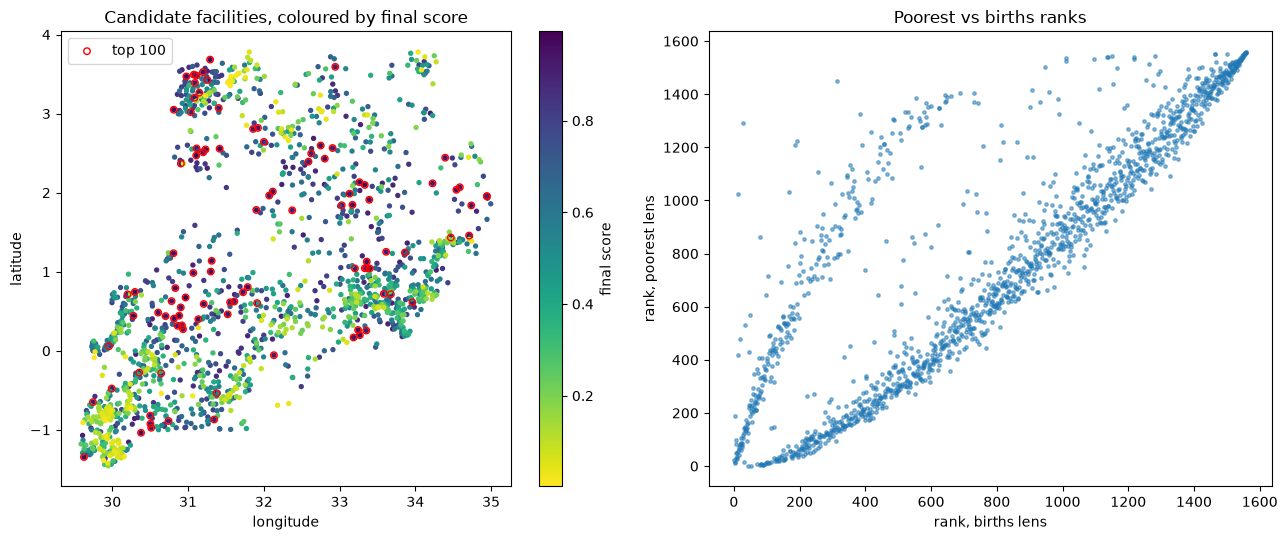

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
sc = ax[0].scatter(P.LONG, P.LAT, c=P.final_score, s=8, cmap="viridis_r")
top = P.head(100); ax[0].scatter(top.LONG, top.LAT, s=22, facecolors="none", edgecolors="red", label="top 100")
ax[0].set_title("Candidate facilities, coloured by final score"); ax[0].set_xlabel("longitude"); ax[0].set_ylabel("latitude")
ax[0].legend(); fig.colorbar(sc, ax=ax[0], label="final score")
ax[1].scatter(P.rank_B, P.rank_P, s=6, alpha=.5)
ax[1].set_xlabel("rank, births lens"); ax[1].set_ylabel("rank, poorest lens"); ax[1].set_title("Poorest vs births ranks")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "ranking_overview.png"), dpi=150); plt.show()

## Part 2. Spend the USD 1,000,000

**Cost model (assumptions, all in the parameter cell):**
- Base cost USD 17,700 per facility, scaled by the facility's daily energy need relative to the pool average, raised to the power 0.6 and clipped to 0.4 to 3.0 times the base (so large facilities cost more, with economies of scale). Missing energy values use the median for the facility's level.
- Grid-extension and solar routes use the same cost in the base case, because no sourced grid cost was found. A scenario below halves the grid-route cost.
- A 10% maintenance reserve is held back before spending.

Facilities are funded in rank order; any that no longer fit are skipped and the next is tried.

In [9]:
df = ranking.copy().reset_index(drop=True)
lvl_med = df.groupby("LEVEL").Avg_kWh_d.transform("median")
df["kwh_d"] = df.Avg_kWh_d.fillna(lvl_med).fillna(df.Avg_kWh_d.median())
df["energy_scale"] = ((df.kwh_d / df.kwh_d.mean()) ** SCALE_EXP).clip(*SCALE_CLIP)
df["is_grid"] = df.route.eq("grid extension")

def cost_vector(mult=1.0, grid_discount=GRID_DISCOUNT):
    c = BASE_COST * mult * df.energy_scale
    return np.where(df.is_grid, c * grid_discount, c)

def select(order_col, ascending, cost, budget):
    idx = df.sort_values(order_col, ascending=ascending).index
    left, chosen = budget, []
    for i in idx:
        if cost[i] <= left:
            chosen.append(i); left -= cost[i]
    return chosen, budget - left

usable = BUDGET * (1 - MAINT_RESERVE)
cost = cost_vector()
df["est_cost"] = cost
df["value_pop_per_usd"] = df["pop"] / df.est_cost
print(f"Budget {BUDGET:,}; maintenance reserve {BUDGET*MAINT_RESERVE:,.0f}; investable {usable:,.0f}")
print(f"Estimated cost per candidate: mean {df.est_cost.mean():,.0f}, min {df.est_cost.min():,.0f}, max {df.est_cost.max():,.0f} (pool mean energy need {df.kwh_d.mean():.1f} kWh/day)")

def summarize(name, chosen, spent):
    s = df.loc[chosen]
    return {"plan": name, "facilities": len(chosen), "spent": round(spent), "people_reached": int(s["pop"].sum()),
            "births_idx": int(s.births_idx.sum()), "poor_people_idx": int(s.poor_people.sum()),
            "cost_per_person": round(spent / s["pop"].sum(), 2), "avg_cost": round(spent / len(chosen)),
            "grid_route": int(s.is_grid.sum()), "solar_route": int((~s.is_grid).sum()),
            **{f"n_{r}": int((s[REGION_COL] == r).sum()) for r in sorted(df[REGION_COL].unique())}}

plans = {"FINAL (2P+3B+1R)": select("rank_final", True, cost, usable),
         "Lens P: poorest": select("rank_P", True, cost, usable),
         "Lens B: births": select("rank_B", True, cost, usable),
         "Lens R: regional": select("rank_R", True, cost, usable),
         "Value for money (pop per USD)": select("value_pop_per_usd", False, cost, usable)}
summ = pd.DataFrame([summarize(k, v[0], v[1]) for k, v in plans.items()])
summ.to_csv(os.path.join(OUT, "budget_plans_comparison.csv"), index=False)
display(summ)

Budget 1,000,000; maintenance reserve 100,000; investable 900,000
Estimated cost per candidate: mean 14,507, min 10,650, max 53,100 (pool mean energy need 19.4 kWh/day)


,plan,facilities,spent,people_reached,births_idx,poor_people_idx,cost_per_person,avg_cost,grid_route,solar_route,n_Central,n_Eastern,n_Northern,n_Western
0,FINAL (2P+3B+1R),25,896132,511172,333261,382463,1.75,35845,20,5,4,3,9,9
1,Lens P: poorest,49,897583,939914,352596,723009,0.95,18318,41,8,7,7,16,19
2,Lens B: births,23,895232,343866,382790,247026,2.60,38923,17,6,3,1,13,6
3,Lens R: regional,49,897583,928792,350796,699549,0.97,18318,41,8,13,12,12,12
4,Value for money (pop per USD),68,892346,1178079,339989,876807,0.76,13123,57,11,8,10,29,21


### 2.1 The recommended plan (final ranking)

In [10]:
chosen, spent = plans["FINAL (2P+3B+1R)"]
sel = df.loc[chosen].copy().sort_values("rank_final"); sel["cum_cost"] = sel.est_cost.cumsum()
sel.to_csv(os.path.join(OUT, "budget_selected_facilities.csv"), index=False, encoding="utf-8-sig")
print(f"Funded {len(sel)} facilities, spent {spent:,.0f} of {usable:,.0f} investable (+ {BUDGET*MAINT_RESERVE:,.0f} maintenance reserve); "
      f"people reached {sel['pop'].sum():,.0f} at USD {spent/sel['pop'].sum():.2f} per person")
display(sel[["rank_final", "FACILITY_N", "LEVEL", "DISTRICT", REGION_COL, "ELECTRIFIC", "pop", "rwi", "km_grid", "route", "est_cost", "cum_cost"]].round(2))
print("\nBy region:"); display(sel.groupby(REGION_COL).agg(facilities=("FID", "count"), people=("pop", "sum"), cost=("est_cost", "sum")).round(0))
print("By level:"); display(sel.groupby("LEVEL").agg(facilities=("FID", "count"), people=("pop", "sum"), cost=("est_cost", "sum")).round(0))
print("By district:"); display(sel.groupby([REGION_COL, "DISTRICT"]).agg(facilities=("FID", "count"), people=("pop", "sum"), cost=("est_cost", "sum")).round(0).sort_values("cost", ascending=False))
print("Facilities shared with each other plan:", {k: len(set(chosen) & set(v[0])) for k, v in plans.items()})

Funded 25 facilities, spent 896,132 of 900,000 investable (+ 100,000 maintenance reserve); people reached 511,172 at USD 1.75 per person


,rank_final,FACILITY_N,LEVEL,DISTRICT,REGION,ELECTRIFIC,pop,rwi,km_grid,route,est_cost,cum_cost
0,1,Buvuma HC IV,HC IV,Buvuma,Central,Off-grid,19604,-0.12,14.67,solar + battery,53100.00,53100.00
1,2,Kigambo HC III,HC III,Kyegegwa,Western,Off-grid,21752,-0.36,0.01,grid extension,53100.00,106200.00
2,3,Showers Foundation Health Centre HC III,HC III,Nebbi,Northern,Off-grid,19947,-0.27,0.07,grid extension,53100.00,159300.00
3,4,Kiriki HC III,HC III,Kween,Eastern,Off-grid,15604,-0.43,10.64,solar + battery,21423.90,180723.90
4,5,Amugu HC III,HC III,Alebtong,Northern,Off-grid,17731,-0.02,0.18,grid extension,53100.00,233823.90
5,6,Aliapi HC II,HC II,Yumbe,Northern,Off-grid,38327,0.18,1.00,grid extension,13406.46,247230.37
6,7,Kambugu HC III,HC III,Kiboga,Central,Off-grid,16319,-0.03,0.01,grid extension,53100.00,300330.37
7,8,Alito Medical Clinic,Clinic,Kitgum,Northern,Off-grid,21789,-0.16,0.03,grid extension,10650.23,310980.59
8,9,Kataraza HC III,HC III,Kyenjojo,Western,No,15011,-0.39,6.04,solar + battery,53100.00,364080.59
9,10,Kerwa HC II,HC II,Yumbe,Northern,Off-grid,32715,-0.07,0.10,grid extension,13406.46,377487.06



By region:


,facilities,people,cost
REGION,,,
Central,4,73477,172706.0
Eastern,3,54583,87930.0
Northern,9,199624,316370.0
Western,9,183488,319126.0


By level:


,facilities,people,cost
LEVEL,,,
Clinic,1,21789,10650.0
HC II,9,248827,120658.0
HC III,14,220952,711724.0
HC IV,1,19604,53100.0


By district:


facilities  people      cost
REGION   DISTRICT                                 
Central  Buvuma                2   33377  106200.0
Northern Alebtong              2   32805  106200.0
Western  Kabarole              2   29719  106200.0
         Kyegegwa              2   49533   66506.0
         Kiruhura              1   13336   53100.0
Eastern  Kaberamaido           1   12746   53100.0
Central  Kiboga                1   16319   53100.0
Northern Arua                  1   16153   53100.0
         Pakwach               1   13787   53100.0
Western  Kyenjojo              1   15011   53100.0
Northern Nebbi                 1   19947   53100.0
         Yumbe                 2   71042   26813.0
Eastern  Kween                 1   15604   21424.0
Central  Mubende               1   23781   13406.0
Eastern  Kaliro                1   26233   13406.0
Northern Oyam                  1   24101   13406.0
Western  Kisoro                1   26432   13406.0
         Kakumiro              1   24189   13406.0
         Ntungamo              1   25268   13406.0
Northern Kitgum                1   21789   10650.0

Facilities shared with each other plan: {'FINAL (2P+3B+1R)': 25, 'Lens P: poorest': 17, 'Lens B: births': 16, 'Lens R: regional': 17, 'Value for money (pop per USD)': 10}


### 2.2 Sensitivity: higher or lower costs, grid routes, reserve

,scenario,facilities,people,cost_per_person,overlap_with_base_plan,solar_route,n_Central,n_Eastern,n_Northern,n_Western
0,cost x0.5,54,968173,0.93,25,9,8,6,20,20
1,cost x0.75,36,702912,1.28,25,7,4,5,14,13
2,BASE,25,511172,1.75,25,5,4,3,9,9
3,cost x1.5,17,366106,2.42,17,4,3,3,6,5
4,cost x2,12,260353,3.41,12,4,3,1,5,3
5,grid-route facilities at 50% cost,42,795212,1.13,25,8,5,6,14,17
6,maintenance reserve 20%,20,400497,1.97,20,5,3,3,8,6
7,no reserve,27,524854,1.90,24,6,3,4,11,9


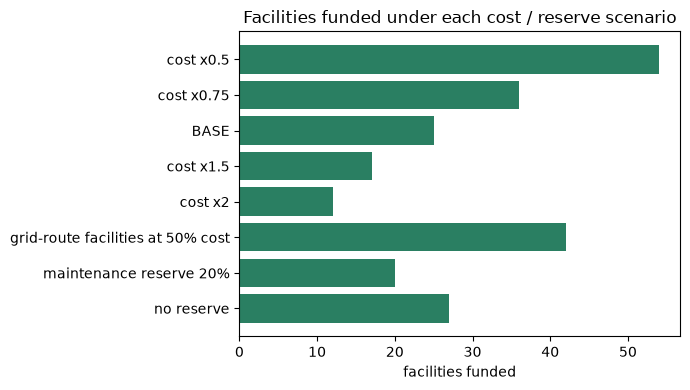

In [11]:
base_set = set(chosen); sens = []
for label, mult, gd, res in [("cost x0.5", .5, GRID_DISCOUNT, MAINT_RESERVE), ("cost x0.75", .75, GRID_DISCOUNT, MAINT_RESERVE),
                             ("BASE", 1.0, GRID_DISCOUNT, MAINT_RESERVE), ("cost x1.5", 1.5, GRID_DISCOUNT, MAINT_RESERVE),
                             ("cost x2", 2.0, GRID_DISCOUNT, MAINT_RESERVE), ("grid-route facilities at 50% cost", 1.0, .5, MAINT_RESERVE),
                             ("maintenance reserve 20%", 1.0, GRID_DISCOUNT, .20), ("no reserve", 1.0, GRID_DISCOUNT, 0.0)]:
    c = cost_vector(mult, gd); ch, sp = select("rank_final", True, c, BUDGET * (1 - res)); s = df.loc[ch]
    sens.append({"scenario": label, "facilities": len(ch), "people": int(s["pop"].sum()), "cost_per_person": round(sp / s["pop"].sum(), 2),
                 "overlap_with_base_plan": len(set(ch) & base_set), "solar_route": int((~s.is_grid).sum()),
                 **{f"n_{r}": int((s[REGION_COL] == r).sum()) for r in sorted(df[REGION_COL].unique())}})
sens = pd.DataFrame(sens); sens.to_csv(os.path.join(OUT, "budget_sensitivity.csv"), index=False)
display(sens)

fig, ax = plt.subplots(figsize=(7, 4))
s2 = sens.set_index("scenario"); ax.barh(s2.index[::-1], s2.facilities[::-1], color="#2a7f62")
ax.set_xlabel("facilities funded"); ax.set_title("Facilities funded under each cost / reserve scenario")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "sensitivity.png"), dpi=150); plt.show()

### 2.3 Where need conflicts with value for money

In [12]:
conflict = df.nsmallest(100, "rank_final").sort_values("value_pop_per_usd").head(10)[
    ["rank_final", "FACILITY_N", "LEVEL", "DISTRICT", "pop", "est_cost", "value_pop_per_usd", "route"]]
print("Among the 100 top-ranked facilities, the ten that reach the fewest people per dollar:")
display(conflict.round(2))
vm = summ.set_index("plan")
print(f"\nFinal plan: {vm.loc['FINAL (2P+3B+1R)','facilities']} facilities, {vm.loc['FINAL (2P+3B+1R)','people_reached']:,} people, "
      f"USD {vm.loc['FINAL (2P+3B+1R)','cost_per_person']}/person;  value-for-money plan: {vm.loc['Value for money (pop per USD)','facilities']} facilities, "
      f"{vm.loc['Value for money (pop per USD)','people_reached']:,} people, USD {vm.loc['Value for money (pop per USD)','cost_per_person']}/person.")

Among the 100 top-ranked facilities, the ten that reach the fewest people per dollar:


,rank_final,FACILITY_N,LEVEL,DISTRICT,pop,est_cost,value_pop_per_usd,route
90,91,Bunjako HC III,HC III,Mpigi,7766,53100.0,0.15,solar + battery (minigrid nearby)
96,97,Paloga HC III,HC III,Lamwo,7782,53100.0,0.15,solar + battery (minigrid nearby)
91,92,Rwoburunga HC III,HC III,Mitooma,7864,53100.0,0.15,grid extension
86,87,Tumboboi HC III,HC III,Kapchorwa,7936,53100.0,0.15,grid extension
85,86,Kazinga HC III,HC III,Kyegegwa,8357,53100.0,0.16,grid extension
87,88,Kibanda HC III,HC III,Rakai,8412,53100.0,0.16,grid extension
94,95,Kicwamba HC III,HC III,Kabarole,8705,53100.0,0.16,grid extension
75,76,Gogonyo HC III,HC III,Pallisa,8922,53100.0,0.17,grid extension
58,59,Matanda HC III,HC III,Kanungu,9145,53100.0,0.17,grid extension
61,62,Namatale HC III,HC III,Buvuma,9437,53100.0,0.18,solar + battery



Final plan: 25 facilities, 511,172 people, USD 1.75/person;  value-for-money plan: 68 facilities, 1,178,079 people, USD 0.76/person.


## Assumptions and limitations (read before using the numbers)

- **Cost per facility is the weakest input.** USD 17,700 is derived from search-result snippets about UNDP's Zimbabwe programme (USD 18.5M for 1,044 systems); the primary source could not be opened. Replace `BASE_COST` with a verified Ministry of Health or programme figure and re-run.
- **Same cost for grid and solar routes** in the base case; a lower grid cost raises the number of facilities funded (see sensitivity).
- **Births are a proxy.** No birth counts exist in the data; facility level (HC III and above run maternity services) stands in.
- **ERT facilities are excluded** as already in the Energy for Rural Transformation programme (assumption); set `EXCLUDE_ERT = False` to include them.
- **"People reached"** uses the facility file's `pop` field. The `Catch_pop` field is rounded and inconsistent, so it is not summed.
- **Regional shares** use the facility catchment population as a stand-in for regional population. The explorer's Population Count layer would be better.
- **Off-grid status** may mean a facility already has solar; grid connection there is an upgrade, not first access.
- **Grid-route cutoff** (5 km) and the **level weights** are judgement calls; change them in the parameter cell.
- **Not used:** irradiation and nighttime-light rasters; the Energy Access Explorer district analysis is documented separately.